<a href="https://colab.research.google.com/github/mhabibier/scikit-learn-cookbook/blob/main/11_Outlier_and_Novelty_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 11 — Outlier and Novelty Detection

**scikit-learn Cookbook, Third Edition — John Sukup (Packt, 2025)**  
**Nama:** Muhammad Habibie Rabbani · **Kelas:** TK-47-04

## Tujuan pembelajaran
Membedakan outlier detection dan novelty detection, menjalankan Isolation Forest/LOF/One-Class SVM, mengorientasikan skor anomali dengan benar, dan menilai tindakan terhadap pengamatan ekstrem.

## Peta reproduksi
Notebook ini mengadaptasi notebook bab utama dan *Exercise Solutions* dari [kode pendamping resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500), commit `c624b1279cf23a83273e806cede15cad0c9e5500`. Penjelasan ditulis ulang dalam Bahasa Indonesia; kode disesuaikan agar dapat dijalankan pada lingkungan yang dicatat di bawah. Penomoran bagian mengikuti alur konsep sumber, bukan nomor halaman PDF. Buku tetap referensi utama untuk membaca uraian lengkap.

| Resep sumber | Bagian |
|---|---|
| Introduction to outlier detection | 1 |
| Isolation Forest | 2 |
| One-Class SVM novelty | 3 |
| Local Outlier Factor | 4 |
| Evaluation | 5 |
| Handling outliers | 6 |
| Choosing techniques | 7 |
| Exercises 1–3 | 8–10 |

## Penyesuaian dan batas reproduksi
Label evaluasi: normal=0, anomali=1. `decision_function` Isolation Forest lebih tinggi untuk normal, sehingga **tandanya dibalik** untuk ROC/AP anomali; ini mengoreksi kode sumber. Distribusi normal training/test novelty menggunakan pusat yang sama, bukan pusat acak yang berbeda. Semua generator diberi seed. Latihan berjudul “real-world/network/manufacturing” pada solusi resmi sebenarnya menggunakan data sintetis; di sini tetap dinyatakan sebagai simulasi dan tidak diklaim data jaringan/sensor nyata.

## Cara menjalankan
Jalankan **Restart Kernel → Run All** dari atas ke bawah. Setiap notebook mandiri. Gunakan Python 3.12 dan paket dalam `requirements.txt`; versi yang benar-benar dipakai tampil di sel pertama. Dataset tersedia melalui scikit-learn atau generator sintetis; tidak memerlukan unduhan data tambahan setelah paket terpasang.

Untuk Google Colab: unggah `.ipynb`, instal versi paket yang diperlukan bila berbeda, lalu **Restart session → Run all**. Pengujian paket ini dilakukan dengan proses IPython baru per notebook, bukan melalui antarmuka Colab.

In [ ]:
%matplotlib inline
import sys, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, f1_score

SEED = 2024
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 115, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 4)
print({'Python': platform.python_version(), 'scikit-learn': sklearn.__version__,
       'NumPy': np.__version__, 'pandas': pd.__version__, 'seed': SEED})

def audit_numeric(X, y=None, name='data'):
    frame = pd.DataFrame(X)
    print(name, {'shape': frame.shape, 'missing': int(frame.isna().sum().sum()),
                 'duplicate_rows': int(frame.duplicated().sum()),
                 'all_finite': bool(np.isfinite(frame.to_numpy(dtype=float)).all())})
    if y is not None and np.asarray(y).ndim == 1:
        display(pd.Series(y).value_counts().sort_index().rename('jumlah').to_frame())

def report(y_true, y_pred, names=None):
    result = classification_report(y_true, y_pred, target_names=names, output_dict=True, zero_division=0)
    overall_accuracy = result.pop('accuracy', None)
    display(pd.DataFrame(result).T)
    if overall_accuracy is not None:
        print(f'Overall accuracy: {overall_accuracy:.4f} (n={len(y_true)})')

def metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0)}

{'Python': '3.12.14', 'scikit-learn': '1.8.0', 'NumPy': '2.3.5', 'pandas': '2.2.3', 'seed': 2024}


## 1. Outlier tidak selalu data salah
Outlier adalah observasi yang berbeda menurut asumsi model atau konteks. Penyebabnya dapat berupa kesalahan ukur, proses baru, serangan, atau variasi sah yang jarang. **Outlier detection** menandai pengamatan pada kumpulan data yang mungkin sudah tercemar. **Novelty detection** mempelajari referensi yang diharapkan normal, lalu menilai observasi baru yang tidak dipakai fitting.

Keluaran estimator umum adalah +1 untuk inlier dan -1 untuk outlier. Ini berbeda dari label evaluasi kita, 0 normal dan 1 anomali. Mengubah representasi label secara eksplisit mencegah salah membaca precision/recall.

Demo pertama mengikuti 300 sampel blobs dan 20 titik uniform sumber. Label “anomali” menunjukkan asal generator; uniform kadang jatuh dekat kelompok normal, sehingga tidak semua titik asal uniform pasti terpisah secara geometris. Tidak ada label yang dipakai saat model fit. Hasil pada data yang sama adalah deteksi dalam-sampel, bukan generalisasi ke data masa depan.

Simulasi blobs + uniform {'shape': (320, 2), 'missing': 0, 'duplicate_rows': 0, 'all_finite': True}


,jumlah
0,300
1,20


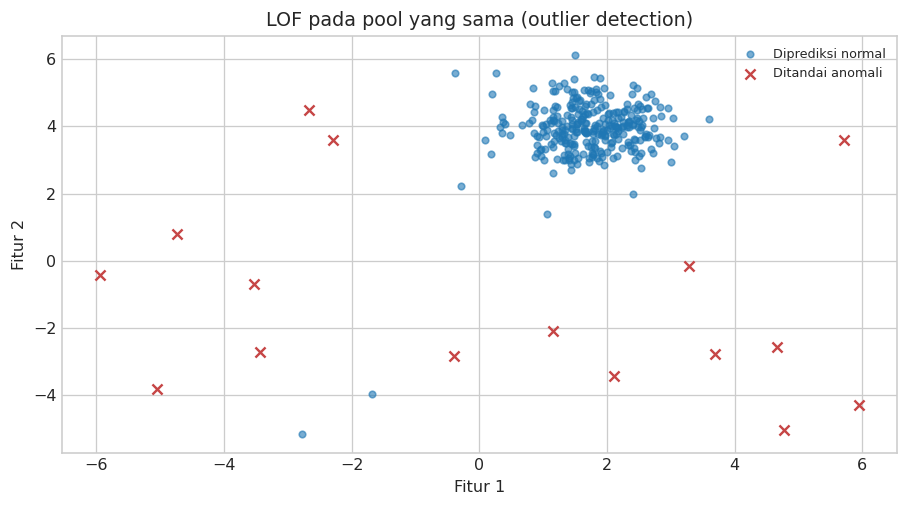

In [ ]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import (ConfusionMatrixDisplay, roc_auc_score, average_precision_score,
                             precision_score, recall_score, RocCurveDisplay, PrecisionRecallDisplay)

def anomaly_result(actual,predicted,score):
    return {'precision_anomaly':precision_score(actual,predicted,zero_division=0),
            'recall_anomaly':recall_score(actual,predicted,zero_division=0),
            'F1_anomaly':f1_score(actual,predicted,zero_division=0),
            'ROC_AUC':roc_auc_score(actual,score),'average_precision':average_precision_score(actual,score),
            'flagged':int(np.sum(predicted))}

def anomaly_plot(ax,X,pred,title):
    mask=np.asarray(pred).astype(bool)
    ax.scatter(X[~mask,0],X[~mask,1],s=17,alpha=.6,label='Diprediksi normal')
    ax.scatter(X[mask,0],X[mask,1],s=40,marker='x',c='#c64646',label='Ditandai anomali')
    ax.set(title=title,xlabel='Fitur 1',ylabel='Fitur 2'); ax.legend(fontsize=8)

normal,_=make_blobs(n_samples=300,centers=1,cluster_std=.6,random_state=SEED)
noise=np.random.default_rng(SEED).uniform(-6,6,(20,2))
X=np.vstack([normal,noise]); truth=np.r_[np.zeros(300,dtype=int),np.ones(20,dtype=int)]
audit_numeric(X,truth,'Simulasi blobs + uniform')
intro_lof=LocalOutlierFactor(n_neighbors=20,contamination=.05)
lof_flags=(intro_lof.fit_predict(X)==-1).astype(int)
fig,ax=plt.subplots(); anomaly_plot(ax,X,lof_flags,'LOF pada pool yang sama (outlier detection)')
plt.tight_layout(); plt.show()

## 2. Isolation Forest
Isolation Forest memilih fitur dan titik potong secara acak untuk mengisolasi sampel. Pengamatan yang mudah dipisahkan cenderung memiliki path yang lebih pendek. Skor mengagregasi panjang path dari banyak pohon. Metode tidak mencari pusat Gaussian tunggal dan relatif efisien, tetapi fitur yang tidak informatif masih dapat mengaburkan sinyal anomali.

`contamination=0.05` menetapkan proporsi acuan untuk threshold pada training; bukan estimasi otomatis bahwa tepat 5% data dunia nyata pasti anomali. Nilai tersebut memengaruhi label akhir, sedangkan ranking skor membawa informasi lebih kaya. Titik normal yang ditandai model adalah false positive menurut label generator.

Di scikit-learn, `score_samples` dan `decision_function` lebih kecil untuk sampel abnormal. Untuk target anomali=1, gunakan **negatif** skornya. Jangan memberikan label -1/+1 sebagai skor kontinu untuk ROC bila ranking asli tersedia.

,model,precision_anomaly,recall_anomaly,F1_anomaly,ROC_AUC,average_precision,flagged
0,IF,1.0,0.8,0.8889,0.9997,0.9955,16
1,LOF,1.0,0.8,0.8889,0.9997,0.9951,16


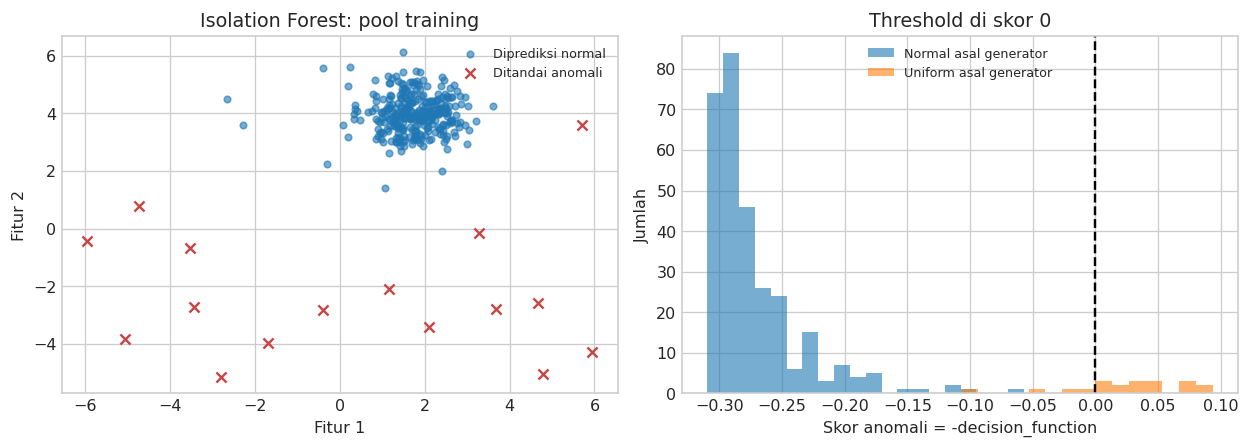

In [ ]:
iso=IsolationForest(n_estimators=100,contamination=.05,random_state=SEED,n_jobs=1).fit(X)
iflags=(iso.predict(X)==-1).astype(int)
iscore=-iso.decision_function(X)
display(pd.DataFrame([{'model':'IF',**anomaly_result(truth,iflags,iscore)},
 {'model':'LOF',**anomaly_result(truth,lof_flags,-intro_lof.negative_outlier_factor_)}]))
fig,axes=plt.subplots(1,2,figsize=(11,4))
anomaly_plot(axes[0],X,iflags,'Isolation Forest: pool training')
axes[1].hist(iscore[truth==0],bins=20,alpha=.6,label='Normal asal generator')
axes[1].hist(iscore[truth==1],bins=15,alpha=.6,label='Uniform asal generator')
axes[1].axvline(0,color='black',ls='--'); axes[1].set(xlabel='Skor anomali = -decision_function',ylabel='Jumlah',title='Threshold di skor 0'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. One-Class SVM untuk novelty detection
One-Class SVM mempelajari batas dukungan distribusi referensi. Kernel RBF dapat membentuk batas nonlinear; gamma menentukan lokalitas. Parameter $\nu\in(0,1]$ merupakan upper bound fraksi training errors dan lower bound fraksi support vectors dalam formulasi ideal, dengan toleransi numerik; **bukan probabilitas anomali baru**.

Training di sini berisi 300 sampel normal dengan pusat [0,0]. Test normal juga berasal dari pusat yang sama dengan seed berbeda, ditambah 20 titik uniform. Pada sumber, pusat normal training/test dibangkitkan berbeda sehingga shift yang tidak disengaja dapat membuat “normal test” ditolak. Perbaikan ini menjaga pertanyaan eksperimen tetap: mendeteksi penyimpangan dari distribusi referensi.

Scaler hanya fit pada normal training. Tidak ada tuning berdasarkan label test. `LOF(novelty=True)` juga diperagakan pada data baru; mode ini tidak boleh digunakan untuk menilai ulang data training dengan `predict` seolah-olah itu novelty.

,model,precision_anomaly,recall_anomaly,F1_anomaly,ROC_AUC,average_precision,flagged
0,One-Class SVM,0.8333,1.0,0.9091,1.0,1.0,24
1,LOF novelty=True,1.0000,1.0,1.0000,1.0,1.0,20


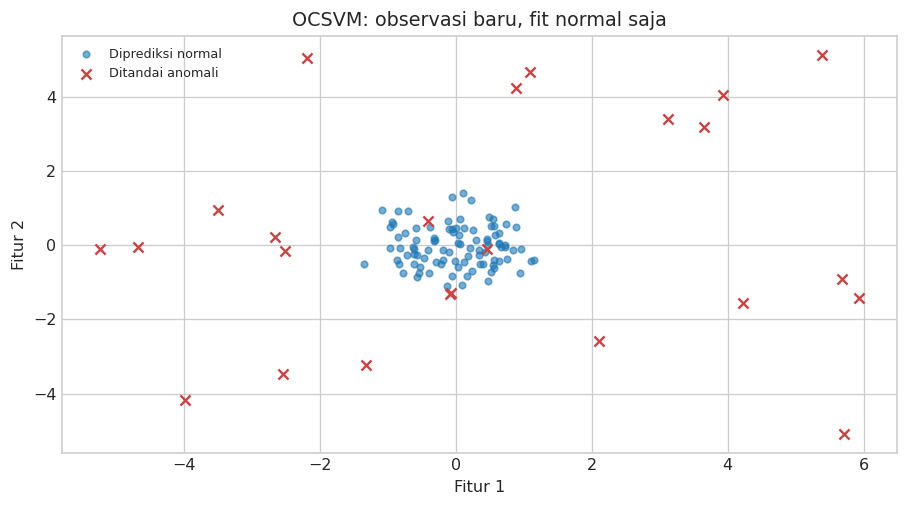

In [ ]:
Nt,_=make_blobs(n_samples=300,centers=[[0,0]],cluster_std=.6,random_state=SEED)
Nv,_=make_blobs(n_samples=100,centers=[[0,0]],cluster_std=.6,random_state=2025)
novel=np.random.default_rng(2025).uniform(-6,6,(20,2))
Neval=np.vstack([Nv,novel]); neval=np.r_[np.zeros(100,dtype=int),np.ones(20,dtype=int)]
oc=make_pipeline(StandardScaler(),OneClassSVM(kernel='rbf',gamma='scale',nu=.05)).fit(Nt)
npred=(oc.predict(Neval)==-1).astype(int); nscore=-oc.decision_function(Neval)
lof_novel=make_pipeline(StandardScaler(),LocalOutlierFactor(n_neighbors=20,contamination=.05,novelty=True)).fit(Nt)
lnpred=(lof_novel.predict(Neval)==-1).astype(int)
display(pd.DataFrame([{'model':'One-Class SVM',**anomaly_result(neval,npred,nscore)},
 {'model':'LOF novelty=True',**anomaly_result(neval,lnpred,-lof_novel.decision_function(Neval))}]))
fig,ax=plt.subplots(); anomaly_plot(ax,Neval,npred,'OCSVM: observasi baru, fit normal saja')
plt.tight_layout(); plt.show()

## 4. Local Outlier Factor pada kepadatan berbeda
LOF membandingkan local reachability density suatu sampel dengan tetangganya. Titik dapat dianggap normal dalam cluster renggang meskipun jauh dari titik lain secara absolut, tetapi abnormal jika kepadatannya rendah relatif terhadap lingkungan lokal.

`n_neighbors` menentukan skala lokal. Terlalu kecil membuat skor sensitif terhadap noise; terlalu besar mengaburkan struktur kecil. Jarak tetap sensitif terhadap skala fitur dan dimensi tinggi. Dua cluster sumber memiliki simpangan baku 0,5 dan 1,5; 20 titik uniform ditambahkan. Mode default memakai `fit_predict` pada pool yang dianalisis. Skor training terdapat pada `negative_outlier_factor_`, bukan `decision_function` default.

{'precision_anomaly': 0.8095238095238095, 'recall_anomaly': 0.85, 'F1_anomaly': 0.8292682926829268, 'ROC_AUC': 0.961375, 'average_precision': 0.8362026545444093, 'flagged': 21}


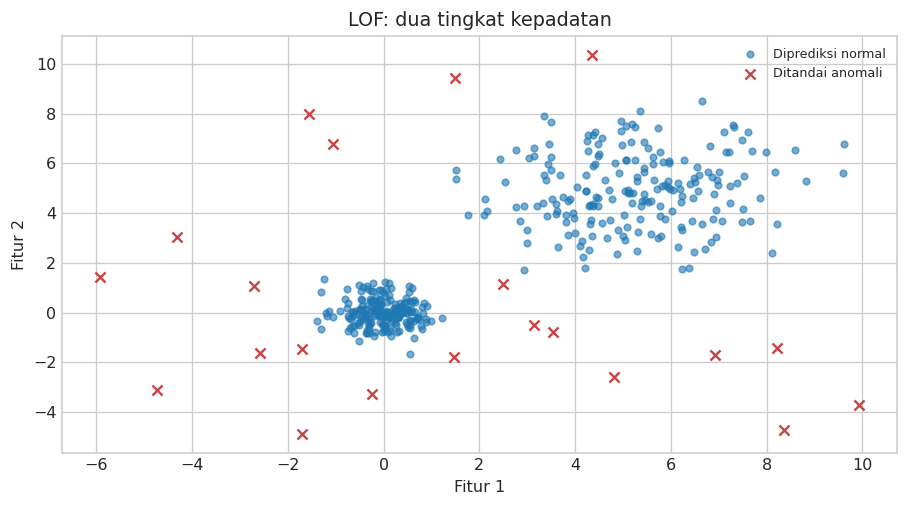

In [ ]:
clusters,_=make_blobs(n_samples=400,centers=[[0,0],[5,5]],cluster_std=[.5,1.5],random_state=SEED)
local_noise=np.random.default_rng(SEED).uniform(-6,10,(20,2))
L=np.vstack([clusters,local_noise]); ltruth=np.r_[np.zeros(400,dtype=int),np.ones(20,dtype=int)]
local=LocalOutlierFactor(n_neighbors=20,contamination=.05)
lp=(local.fit_predict(L)==-1).astype(int)
print(anomaly_result(ltruth,lp,-local.negative_outlier_factor_))
fig,ax=plt.subplots(); anomaly_plot(ax,L,lp,'LOF: dua tingkat kepadatan'); plt.tight_layout(); plt.show()

## 5. Evaluasi dengan arah skor yang benar
Accuracy dapat tinggi hanya dengan menyebut semua sampel normal ketika anomali jarang. Precision menilai proporsi alarm yang benar, recall menilai proporsi anomali yang ditemukan, dan average precision merangkum ranking pada kurva PR. Baseline precision acak setara prevalensi anomali. ROC-AUC menggunakan ranking pada seluruh threshold dan tidak menentukan threshold operasional.

Resep sumber memfit dan menilai Isolation Forest pada 300 normal + 30 outlier yang sama. Kita pertahankan untuk reproduksi **transduktif**, dan membedakannya dari novelty holdout pada Bagian 3. Label generator dipakai hanya untuk evaluasi. Contamination=0,09 adalah konfigurasi simulasi; menebaknya dari label operasional yang tidak tersedia tidak diperbolehkan.

Overall accuracy: 0.9636 (n=330)
AUC jika arah skor keliru: 0.03688888888888888 AUC dengan orientasi benar: 0.9631111111111113


,precision_anomaly,recall_anomaly,F1_anomaly,ROC_AUC,average_precision,flagged
0,0.8,0.8,0.8,0.9631,0.8751,30


,precision,recall,f1-score,support
Normal,0.9800,0.9800,0.9800,300.0
Anomali,0.8000,0.8000,0.8000,30.0
macro avg,0.8900,0.8900,0.8900,330.0
weighted avg,0.9636,0.9636,0.9636,330.0


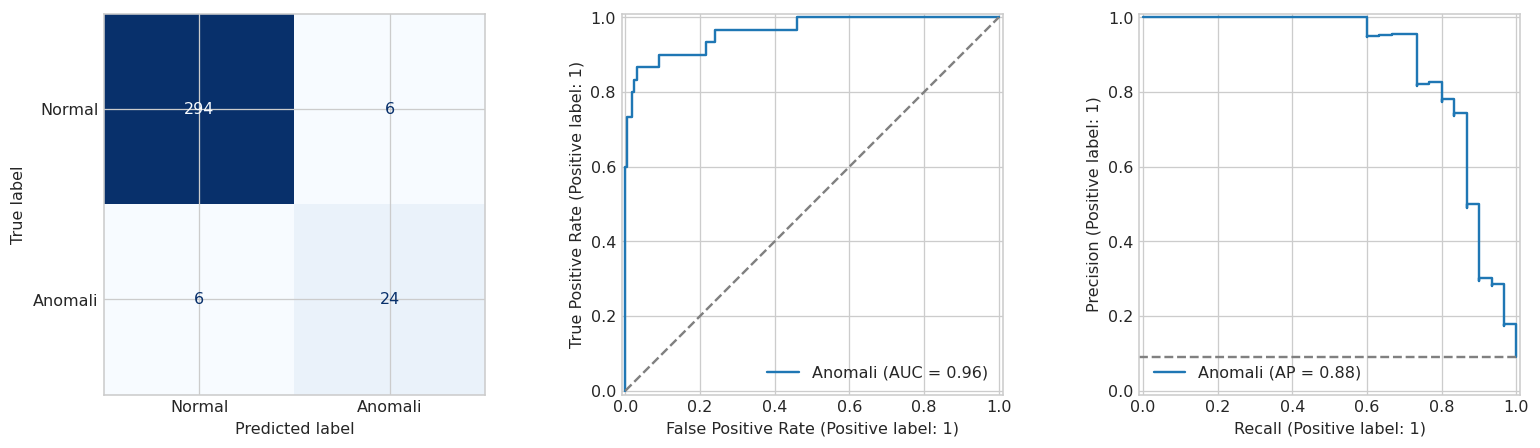

In [ ]:
En,_=make_blobs(n_samples=300,centers=[[0,0]],cluster_std=.6,random_state=SEED)
Eo=np.random.default_rng(2026).uniform(-6,6,(30,2)); E=np.vstack([En,Eo])
ey=np.r_[np.zeros(300,dtype=int),np.ones(30,dtype=int)]
evaluate_if=IsolationForest(contamination=.09,random_state=SEED,n_jobs=1).fit(E)
ep=(evaluate_if.predict(E)==-1).astype(int); es=-evaluate_if.decision_function(E)
evaluation=anomaly_result(ey,ep,es); display(pd.DataFrame([evaluation])); report(ey,ep,['Normal','Anomali'])
fig,axes=plt.subplots(1,3,figsize=(14,4))
ConfusionMatrixDisplay.from_predictions(ey,ep,display_labels=['Normal','Anomali'],cmap='Blues',colorbar=False,ax=axes[0])
RocCurveDisplay.from_predictions(ey,es,ax=axes[1],name='Anomali'); axes[1].plot([0,1],[0,1],'--',color='gray')
PrecisionRecallDisplay.from_predictions(ey,es,ax=axes[2],name='Anomali'); axes[2].axhline(ey.mean(),ls='--',color='gray')
plt.tight_layout(); plt.show()
print('AUC jika arah skor keliru:',roc_auc_score(ey,-es),'AUC dengan orientasi benar:',evaluation['ROC_AUC'])

## 6. Menangani outlier: mempertahankan, menghapus, mengganti, membatasi
Alarm model adalah alasan menyelidiki, bukan izin menghapus data. Penghapusan dapat menghilangkan kelompok minoritas sah. Mengganti satu baris dengan median menghapus hubungan antarfitur dan bisa membuat banyak baris identik. Winsorization membatasi nilai per fitur pada kuantil tertentu; ia dapat memotong observasi sah dan tidak sama dengan deteksi multivariat.

Bagian ini memperagakan tindakan pada salinan pool sumber untuk melihat konsekuensinya. Dataset asli tidak diubah. Dalam supervised pipeline, detector/batas kuantil hanya dipelajari pada training. Jangan membuang sampel test yang sulit lalu melaporkan skor meningkat. Jika baris training dihapus, pasangan labelnya harus dihapus dengan mask yang sama.

{'original_rows': 330, 'after_removal': 300, 'median_replaced_rows': 30, 'rows_changed_by_capping': 51}


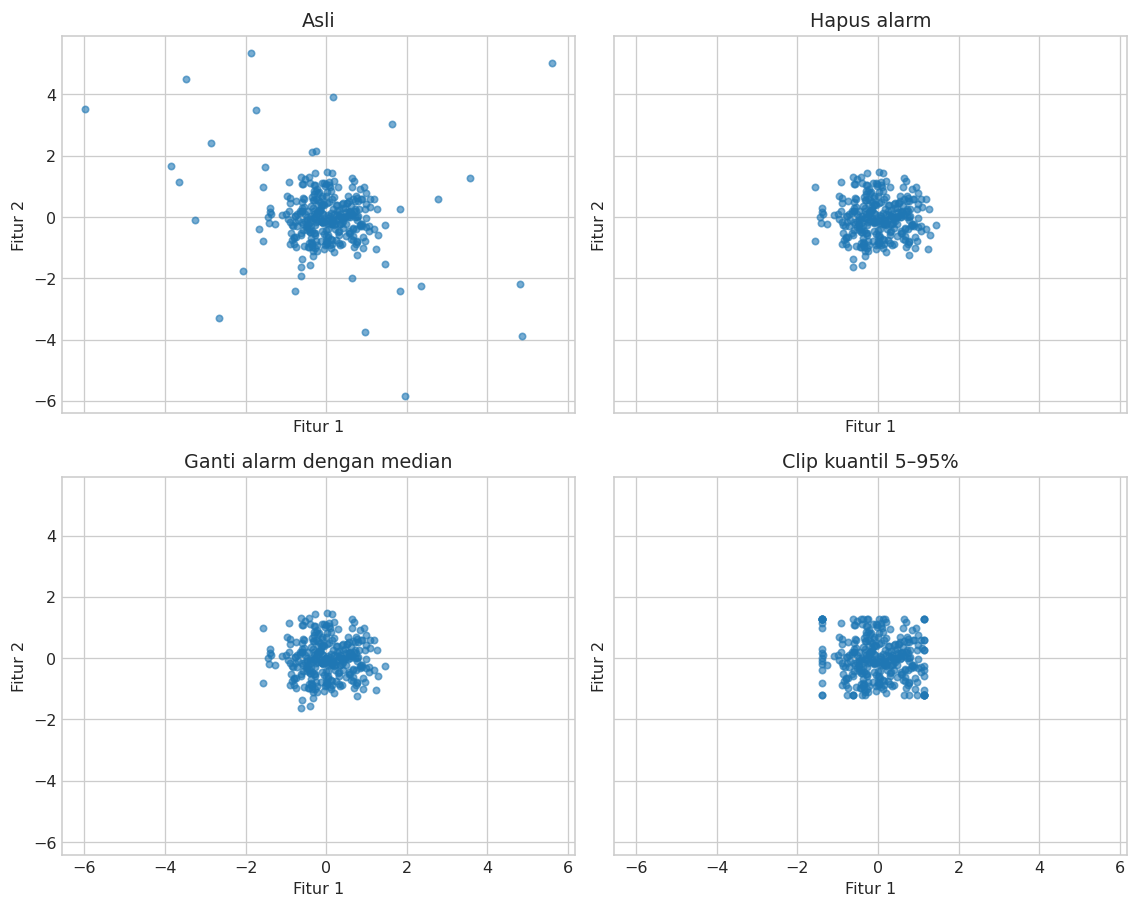

In [ ]:
flag=ep.astype(bool)
removed=E[~flag].copy()
replaced=E.copy(); replaced[flag]=np.median(E[~flag],axis=0)
lower,upper=np.quantile(E,[.05,.95],axis=0); capped=np.clip(E,lower,upper)
print({'original_rows':len(E),'after_removal':len(removed),'median_replaced_rows':int(flag.sum()),
       'rows_changed_by_capping':int(np.any(capped!=E,axis=1).sum())})
fig,axes=plt.subplots(2,2,figsize=(10,8),sharex=True,sharey=True)
for ax,(name,data) in zip(axes.flat,[('Asli',E),('Hapus alarm',removed),('Ganti alarm dengan median',replaced),('Clip kuantil 5–95%',capped)]):
    ax.scatter(data[:,0],data[:,1],s=16,alpha=.6); ax.set(title=name,xlabel='Fitur 1',ylabel='Fitur 2')
plt.tight_layout(); plt.show()

## 7. Memilih teknik sesuai pertanyaan
| Teknik | Referensi training | Prediksi observasi baru | Kekuatan dan keterbatasan |
|---|---|---|---|
| Isolation Forest | Pool tanpa label, dapat tercemar | Ya | Relatif efisien; fitur tak informatif dapat mengaburkan sinyal |
| LOF default | Pool yang dianalisis | Tidak melalui `predict` default | Anomali lokal; sensitif tetangga dan jarak |
| LOF novelty=True | Referensi yang diharapkan bersih | Ya, khusus data baru | Perlu membedakan mode novelty dan outlier |
| One-Class SVM | Referensi yang diharapkan normal | Ya | Batas nonlinear; sensitif scaling, nu, gamma, dan jumlah sampel |

Ketiganya tidak memerlukan target supervised untuk fitting. Normalitas referensi merupakan asumsi proses pengumpulan data. Untuk log keamanan/sensor, evaluasi temporal dan keterlambatan label lebih realistis daripada random split. Pilih threshold berdasarkan validation dan kapasitas pemeriksaan alarm; jangan mengklaim setiap alarm sebagai serangan.

## 8. Latihan 1 — Isolation Forest pada simulasi berlabel
Solusi resmi berjudul “real-world dataset” tetapi menggunakan `make_blobs` dan uniform. Latihan ini mereproduksi simulasi 300+30 dengan scaling dan contamination 0,09. Standardisasi di sini fit pada pool yang sama karena tugasnya deteksi dalam-sampel. Untuk penggunaan baru, gunakan pola training/test Bagian 3.

In [ ]:
ex1=make_pipeline(StandardScaler(),IsolationForest(contamination=.09,random_state=SEED,n_jobs=1)).fit(E)
ex1p=(ex1.predict(E)==-1).astype(int)
print('Latihan 1 — simulated data:',anomaly_result(ey,ex1p,-ex1.decision_function(E)))
report(ey,ex1p,['Normal','Anomali'])

Latihan 1 — simulated data: {'precision_anomaly': 0.8, 'recall_anomaly': 0.8, 'F1_anomaly': 0.8, 'ROC_AUC': 0.9631111111111113, 'average_precision': 0.8751115159166343, 'flagged': 30}
Overall accuracy: 0.9636 (n=330)


,precision,recall,f1-score,support
Normal,0.9800,0.9800,0.9800,300.0
Anomali,0.8000,0.8000,0.8000,30.0
macro avg,0.8900,0.8900,0.8900,330.0
weighted avg,0.9636,0.9636,0.9636,330.0


## 9. Latihan 2 — LOF pada simulasi kepadatan
Data dua cluster 400+20 berasal dari generator yang sama dengan Bagian 4, kemudian distandardisasi sesuai latihan sumber. Nama “network intrusion” hanya konteks ilustratif; kedua koordinat bukan fitur traffic jaringan. Nilai metrik tidak membuktikan kemampuan mendeteksi serangan nyata.

Latihan 2 — simulated data: {'precision_anomaly': 0.8095238095238095, 'recall_anomaly': 0.85, 'F1_anomaly': 0.8292682926829268, 'ROC_AUC': 0.96275, 'average_precision': 0.8403206517317394, 'flagged': 21}


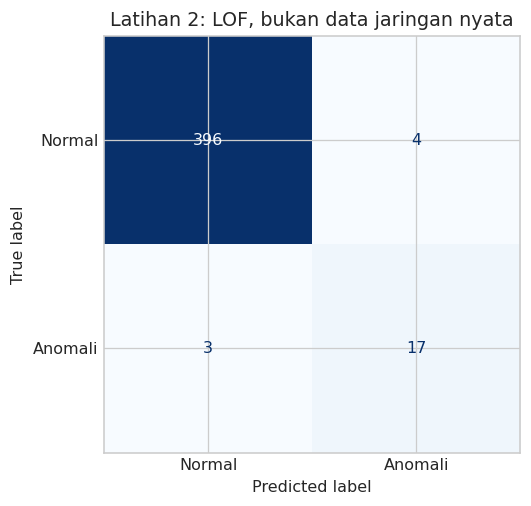

In [ ]:
Ls=StandardScaler().fit_transform(L)
ex2=LocalOutlierFactor(n_neighbors=20,contamination=.05)
ex2p=(ex2.fit_predict(Ls)==-1).astype(int)
print('Latihan 2 — simulated data:',anomaly_result(ltruth,ex2p,-ex2.negative_outlier_factor_))
fig,ax=plt.subplots(); ConfusionMatrixDisplay.from_predictions(ltruth,ex2p,display_labels=['Normal','Anomali'],cmap='Blues',colorbar=False,ax=ax)
ax.set_title('Latihan 2: LOF, bukan data jaringan nyata'); plt.tight_layout(); plt.show()

## 10. Latihan 3 — novelty pada dua sensor simulasi
Tiga ratus pengamatan normal dibangkitkan dari Gaussian dengan mean 0 dan simpangan baku 0,5. Sebanyak 20% normal disisihkan untuk test dan ditambah 30 titik uniform. Model tidak pernah fit pada novelty. Seed membuat eksperimen dapat diulang, tetapi tidak membuat simulasi otomatis representatif terhadap sensor pabrik. Pada sensor nyata, unit, kalibrasi, autokorelasi waktu dan perubahan kondisi operasi perlu diperhitungkan.

Latihan 3: {'precision_anomaly': 0.7777777777777778, 'recall_anomaly': 0.9333333333333333, 'F1_anomaly': 0.8484848484848485, 'ROC_AUC': 0.9827777777777779, 'average_precision': 0.9757484353061565, 'flagged': 36}


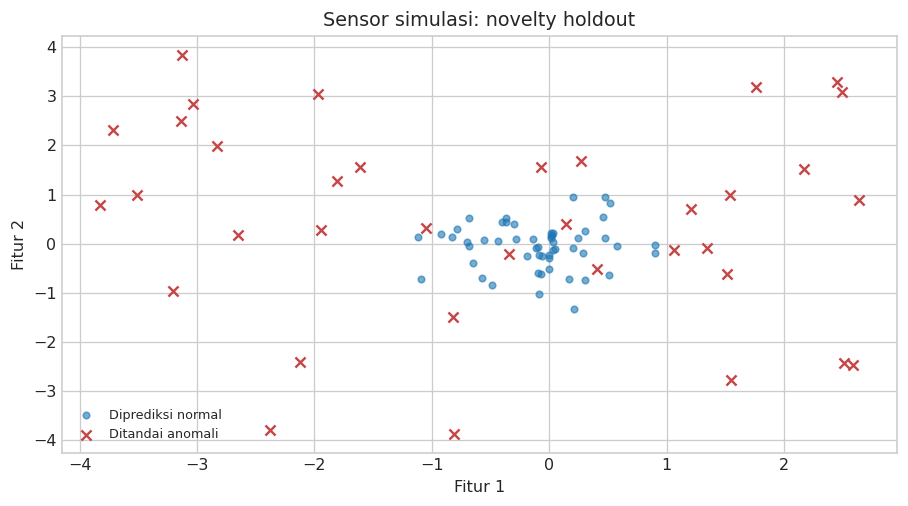

**Analisis hasil:** alarm dapat muncul pada sampel normal dan beberapa novelty dapat lolos, terutama bila nilai uniform jatuh dekat distribusi normal. Interpretasikan precision/recall berdasarkan ambang yang ditetapkan, bukan menghapus titik yang membuat skor turun.

In [ ]:
rng=np.random.default_rng(SEED)
sensor_normal=rng.normal(0,.5,(300,2)); sensor_novel=rng.uniform(-4,4,(30,2))
sensor_train,sensor_test=train_test_split(sensor_normal,test_size=.2,random_state=SEED)
sensor_eval=np.vstack([sensor_test,sensor_novel]); sensor_y=np.r_[np.zeros(len(sensor_test),dtype=int),np.ones(30,dtype=int)]
sensor_model=make_pipeline(StandardScaler(),OneClassSVM(kernel='rbf',gamma='scale',nu=.05)).fit(sensor_train)
sensor_pred=(sensor_model.predict(sensor_eval)==-1).astype(int)
print('Latihan 3:',anomaly_result(sensor_y,sensor_pred,-sensor_model.decision_function(sensor_eval)))
fig,ax=plt.subplots(); anomaly_plot(ax,sensor_eval,sensor_pred,'Sensor simulasi: novelty holdout'); plt.tight_layout(); plt.show()
display(Markdown('**Analisis hasil:** alarm dapat muncul pada sampel normal dan beberapa novelty dapat lolos, terutama bila nilai uniform jatuh dekat distribusi normal. '
 'Interpretasikan precision/recall berdasarkan ambang yang ditetapkan, bukan menghapus titik yang membuat skor turun.'))

## Ringkasan chapter
Outlier detection menganalisis pool yang dapat tercemar, sedangkan novelty detection menilai observasi baru terhadap referensi normal. Isolation Forest, LOF, dan One-Class SVM memakai asumsi berbeda. Orientasi skor, arti label, threshold, serta status in-sample/holdout wajib dinyatakan. Penanganan outlier membutuhkan pengetahuan domain; skor anomali bukan bukti data salah atau serangan.

## Refleksi untuk dikerjakan sendiri
1. Mengapa membalik tanda skor Isolation Forest penting saat anomali diberi label 1?
2. Apa yang terjadi bila normal training dan normal test berasal dari pusat yang berbeda?
3. Mengapa menghapus semua alarm dapat menghilangkan kejadian penting?
4. Bagaimana Anda akan menilai detector pada sensor parkir atau log keamanan yang berurutan dalam waktu?

## Referensi dan atribusi
- John Sukup. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Kode pendamping Chapter 11 dan solusi latihan: [repository resmi](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition/tree/c624b1279cf23a83273e806cede15cad0c9e5500).
- [Novelty and outlier detection](https://scikit-learn.org/1.8/modules/outlier_detection.html).
- [LocalOutlierFactor API](https://scikit-learn.org/1.8/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).
- [IsolationForest API](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.IsolationForest.html).
- Kode sumber pendamping berlisensi MIT; teks lisensi dipertahankan pada `THIRD_PARTY_NOTICES.md`. Penjelasan, koreksi metodologi, dan eksperimen tambahan pada notebook ini merupakan adaptasi belajar berbantuan AI. Baca, jalankan ulang, dan tulis refleksi pribadi sebelum menyerahkan tugas; jangan menyatakan bagian berbantuan AI sebagai pekerjaan mandiri tanpa mengikuti kebijakan kelas.